# ĐỀ TÀI: XỬ LÝ VIDEO SONG SONG THEO TỪNG FRAME BẰNG OPENMP

### Mục tiêu nghiên cứu & triển khai:
1. **Phân rã bài toán**: Quá trình giải mã (decode) và nén (encode) video có tính tuần tự, trong khi các phép biến đổi ảnh (Sobel Edge, Gaussian Blur, Cartoon filter) trên từng khung hình độc lập có tính chất song song tự nhiên (**Embarrassingly Parallel**).
2. **Kiến trúc Lô (Batch/Chunk Processing)**:
   - Đọc một nhóm $B$ frames vào bộ nhớ đệm (RAM).
   - Sử dụng chỉ thị song song OpenMP: `#pragma omp parallel for schedule(dynamic)` để phân bổ các khung hình cho các CPU threads xử lý đồng thời.
   - Thu thập kết quả và ghi tuần tự theo đúng thứ tự thời gian vào video đầu ra.
3. **Đánh giá hiệu năng**:
   - So sánh thời gian xử lý: **Tuần tự (1 thread)** vs **Song song (2, 4, 8 threads)**.
   - Tính toán hệ số tăng tốc (**Speedup** = $T_{seq} / T_{par}$) và tốc độ khung hình (**FPS**).

## Bước 1: Cài đặt công cụ biên dịch & OpenCV trên hệ thống (Linux / JupyterLab)

In [1]:
# Cài đặt trình biên dịch g++, libomp và thư viện lập trình ảnh OpenCV
!apt-get update && apt-get install -y build-essential libomp-dev libopencv-dev python3-opencv

Get:1 https://download.docker.com/linux/debian trixie InRelease [32.5 kB]
Hit:2 https://playit-cloud.github.io/ppa/data ./ InRelease                     
Hit:3 https://deb.nodesource.com/node_22.x nodistro InRelease                  
Hit:4 https://dl.google.com/linux/chrome/deb stable InRelease                  
Hit:5 http://security.debian.org/debian-security trixie-security InRelease     
Hit:6 http://deb.debian.org/debian trixie InRelease                            
Hit:7 http://deb.debian.org/debian trixie-updates InRelease                    
Hit:8 http://download.proxmox.com/debian/ceph-squid trixie InRelease           
Hit:9 http://download.proxmox.com/debian/pve trixie InRelease
Get:10 https://developer.download.nvidia.com/compute/cuda/repos/debian12/x86_64  InRelease [1,578 B]
Err:10 https://developer.download.nvidia.com/compute/cuda/repos/debian12/x86_64  InRelease
  Sub-process /usr/bin/sqv returned an error code (1), error message is: Signing key on EB693B3035CD5710E231E123

## Bước 2: Tạo video mẫu để kiểm thử hiệu năng (Sample Video Generator)

In [2]:
import cv2
import numpy as np
import os

def generate_video(filename="sample_video.mp4", duration_sec=6, fps=30, width=1280, height=720):
    total_frames = duration_sec * fps
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(filename, fourcc, fps, (width, height))
    
    print(f"[*] Đang khởi tạo video '{filename}' ({width}x{height}, {total_frames} frames)...")
    for i in range(total_frames):
        frame = np.zeros((height, width, 3), dtype=np.uint8)
        t = i / float(total_frames)
        
        # Nền màu chuyển động
        r = int(127 + 127 * np.sin(2 * np.pi * t))
        g = int(127 + 127 * np.cos(2 * np.pi * t))
        b = int(127 + 127 * np.sin(4 * np.pi * t))
        frame[:] = (b, g, r)
        
        # Hình khối chuyển động
        cx = int(width/2 + (width/3) * np.cos(4 * np.pi * t))
        cy = int(height/2 + (height/3) * np.sin(4 * np.pi * t))
        cv2.circle(frame, (cx, cy), 65, (0, 255, 255), -1)
        
        cv2.putText(frame, f"Frame {i+1}/{total_frames} - OpenMP Parallel Processing", (40, 70),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.1, (255, 255, 255), 2)
        
        # Thêm nhiễu ngẫu nhiên để tăng độ phức tạp khi tính toán lọc ảnh
        noise = np.random.randint(0, 30, (height, width, 3), dtype=np.uint8)
        frame = cv2.add(frame, noise)
        
        out.write(frame)
        
    out.release()
    print(f"[+] Đã tạo xong video thành công: {filename} ({os.path.getsize(filename)/(1024*1024):.2f} MB)")

generate_video("sample_video.mp4")

[*] Đang khởi tạo video 'sample_video.mp4' (1280x720, 180 frames)...
[+] Đã tạo xong video thành công: sample_video.mp4 (27.01 MB)


## Bước 3: Tạo mã nguồn C++ sử dụng OpenMP để xử lý video song song
Chương trình sử dụng `#pragma omp parallel for` trên các batch khung hình.

In [3]:
%%writefile video_openmp.cpp
#include <iostream>
#include <vector>
#include <string>
#include <chrono>
#include <omp.h>
#include <opencv2/opencv.hpp>

enum FilterType {
    FILTER_SOBEL_EDGES = 1,
    FILTER_GAUSSIAN_BLUR = 2,
    FILTER_CARTOON = 3
};

// Hàm xử lý đơn khung hình (CPU Intensive Filter)
cv::Mat process_single_frame(const cv::Mat& input_frame, FilterType filter_type) {
    if (input_frame.empty()) return input_frame;
    cv::Mat output_frame;

    switch (filter_type) {
        case FILTER_SOBEL_EDGES: {
            cv::Mat gray, grad_x, grad_y, abs_grad_x, abs_grad_y;
            cv::cvtColor(input_frame, gray, cv::COLOR_BGR2GRAY);
            cv::GaussianBlur(gray, gray, cv::Size(3, 3), 0, 0);
            cv::Sobel(gray, grad_x, CV_16S, 1, 0, 3);
            cv::Sobel(gray, grad_y, CV_16S, 0, 1, 3);
            cv::convertScaleAbs(grad_x, abs_grad_x);
            cv::convertScaleAbs(grad_y, abs_grad_y);
            cv::Mat edge;
            cv::addWeighted(abs_grad_x, 0.5, abs_grad_y, 0.5, 0, edge);
            cv::cvtColor(edge, output_frame, cv::COLOR_GRAY2BGR);
            break;
        }
        case FILTER_GAUSSIAN_BLUR: {
            cv::Mat temp = input_frame.clone();
            for (int k = 0; k < 4; ++k) {
                cv::GaussianBlur(temp, output_frame, cv::Size(15, 15), 0);
                temp = output_frame;
            }
            break;
        }
        case FILTER_CARTOON: {
            cv::Mat gray, edges, color;
            cv::cvtColor(input_frame, gray, cv::COLOR_BGR2GRAY);
            cv::medianBlur(gray, gray, 7);
            cv::adaptiveThreshold(gray, edges, 255, cv::ADAPTIVE_THRESH_MEAN_C, cv::THRESH_BINARY, 9, 2);
            cv::bilateralFilter(input_frame, color, 9, 75, 75);
            cv::Mat edges_bgr;
            cv::cvtColor(edges, edges_bgr, cv::COLOR_GRAY2BGR);
            cv::bitwise_and(color, edges_bgr, output_frame);
            break;
        }
        default:
            output_frame = input_frame.clone();
            break;
    }
    return output_frame;
}

double process_video_openmp(const std::string& input_path, const std::string& output_path, int num_threads, int batch_size = 64, FilterType filter_type = FILTER_SOBEL_EDGES) {
    cv::VideoCapture cap(input_path);
    if (!cap.isOpened()) return -1.0;

    int total_frames = static_cast<int>(cap.get(cv::CAP_PROP_FRAME_COUNT));
    double fps = cap.get(cv::CAP_PROP_FPS);
    int width = static_cast<int>(cap.get(cv::CAP_PROP_FRAME_WIDTH));
    int height = static_cast<int>(cap.get(cv::CAP_PROP_FRAME_HEIGHT));

    cv::VideoWriter writer;
    bool write_to_disk = !output_path.empty();
    if (write_to_disk) {
        int fourcc = cv::VideoWriter::fourcc('m', 'p', '4', 'v');
        writer.open(output_path, fourcc, fps, cv::Size(width, height));
    }

    omp_set_num_threads(num_threads);
    double start_time = omp_get_wtime();
    int processed_frames_count = 0;
    bool is_end = false;

    while (!is_end) {
        std::vector<cv::Mat> batch_inputs;
        batch_inputs.reserve(batch_size);
        for (int i = 0; i < batch_size; ++i) {
            cv::Mat frame;
            if (!cap.read(frame) || frame.empty()) {
                is_end = true;
                break;
            }
            batch_inputs.push_back(frame);
        }
        if (batch_inputs.empty()) break;

        int current_batch_size = static_cast<int>(batch_inputs.size());
        std::vector<cv::Mat> batch_outputs(current_batch_size);

        // PARALLEL FRAME PROCESSING USING OPENMP
        #pragma omp parallel for schedule(dynamic)
        for (int i = 0; i < current_batch_size; ++i) {
            batch_outputs[i] = process_single_frame(batch_inputs[i], filter_type);
        }

        if (write_to_disk) {
            for (int i = 0; i < current_batch_size; ++i) {
                writer.write(batch_outputs[i]);
            }
        }
        processed_frames_count += current_batch_size;
    }

    double end_time = omp_get_wtime();
    double total_time = end_time - start_time;
    double p_fps = (total_time > 0) ? (processed_frames_count / total_time) : 0;

    std::cout << "Threads: " << num_threads 
              << " | Thoi gian: " << total_time << " s"
              << " | Toc do: " << p_fps << " FPS" << std::endl;

    cap.release();
    if (write_to_disk) writer.release();
    return total_time;
}

int main(int argc, char** argv) {
    std::string input = (argc >= 2) ? argv[1] : "sample_video.mp4";
    std::string output = (argc >= 3) ? argv[2] : "output.mp4";
    int filter = (argc >= 4) ? std::stoi(argv[3]) : 1;
    int threads = (argc >= 5) ? std::stoi(argv[4]) : 1;

    process_video_openmp(input, output, threads, 64, static_cast<FilterType>(filter));
    return 0;
}

Overwriting video_openmp.cpp


## Bước 4: Biên dịch mã nguồn C++ với cờ `-fopenmp` và liên kết thư viện OpenCV

In [4]:
!g++ -O3 -fopenmp -std=c++17 video_openmp.cpp -o video_omp -I/usr/include/opencv4 -lopencv_core -lopencv_imgproc -lopencv_videoio -lopencv_highgui
!ls -lh video_omp


-rwxr-xr-x 1 root root 30K Sep 29 15:30 video_omp


## Bước 5: Chạy đo lường hiệu năng thực nghiệm (1, 2, 4, 8 luồng)

In [5]:
import subprocess
import re
import matplotlib.pyplot as plt

threads_test = [1, 2, 4, 8]
times = []
fps_list = []
speedups = []
base_time = None

for t in threads_test:
    out_param = "test_result.mp4" if t == threads_test[-1] else ""
    cmd = f"./video_omp sample_video.mp4 '{out_param}' 1 {t}"
    res = subprocess.run(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)
    stdout = res.stdout
    print(stdout.strip())
    
    m_time = re.search(r"Thoi gian:\s*([\d\.]+)\s*s", stdout)
    m_fps = re.search(r"Toc do:\s*([\d\.]+)\s*FPS", stdout)
    
    if m_time:
        elapsed = float(m_time.group(1))
        fps = float(m_fps.group(1)) if m_fps else 0
        times.append(elapsed)
        fps_list.append(fps)
        if base_time is None:
            base_time = elapsed
        speedups.append(base_time / elapsed)

print("\n[*] Tổng kết kết quả:")
for i, t in enumerate(threads_test):
    print(f"- {t} Luồng: Thời gian = {times[i]:.2f}s | FPS = {fps_list[i]:.1f} | Speedup = {speedups[i]:.2f}x")

Threads: 1 | Thoi gian: 0.485365 s | Toc do: 370.855 FPS
Threads: 2 | Thoi gian: 0.354078 s | Toc do: 508.362 FPS
Threads: 4 | Thoi gian: 0.288235 s | Toc do: 624.491 FPS
Threads: 8 | Thoi gian: 0.9911 s | Toc do: 181.616 FPS

[*] Tổng kết kết quả:
- 1 Luồng: Thời gian = 0.49s | FPS = 370.9 | Speedup = 1.00x
- 2 Luồng: Thời gian = 0.35s | FPS = 508.4 | Speedup = 1.37x
- 4 Luồng: Thời gian = 0.29s | FPS = 624.5 | Speedup = 1.68x
- 8 Luồng: Thời gian = 0.99s | FPS = 181.6 | Speedup = 0.49x


## Bước 6: Trực quan hóa kết quả biểu đồ (Speedup & FPS)

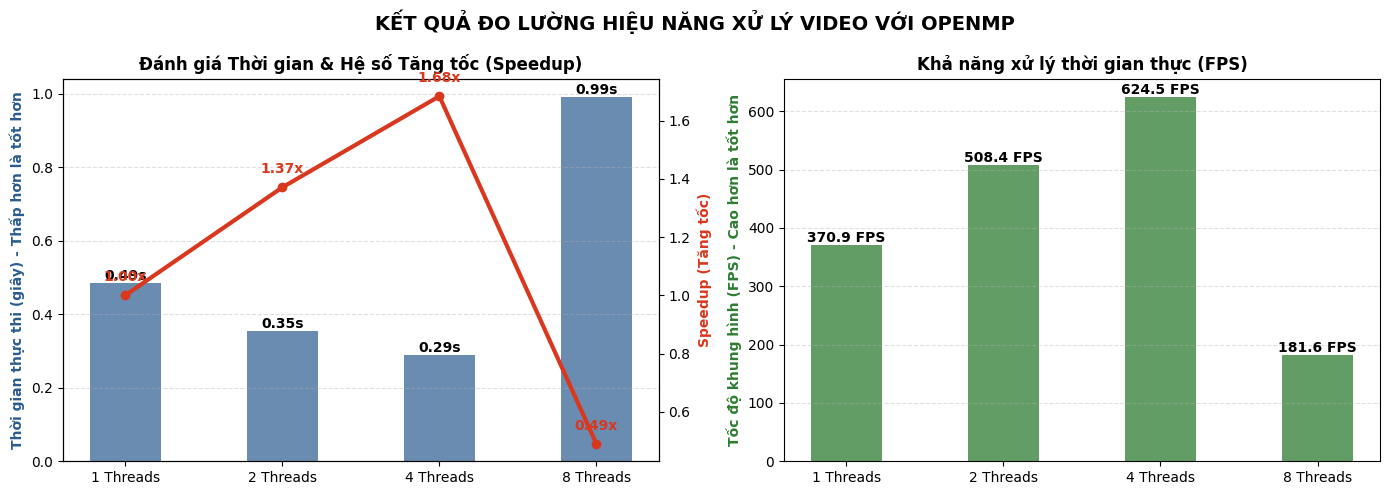

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ thời gian và Speedup
labels = [f"{t} Threads" for t in threads_test]
bars = ax1.bar(labels, times, color='#2b5c8f', width=0.45, alpha=0.7, label='Thời gian (giây)')
ax1.set_ylabel('Thời gian thực thi (giây) - Thấp hơn là tốt hơn', color='#2b5c8f', fontweight='bold')
for b in bars:
    ax1.annotate(f"{b.get_height():.2f}s", (b.get_x() + b.get_width()/2, b.get_height()),
                 ha='center', va='bottom', fontweight='bold')

ax1_twin = ax1.twinx()
ax1_twin.plot(labels, speedups, color='#d9381e', marker='o', linewidth=3, label='Speedup (lần)')
ax1_twin.set_ylabel('Speedup (Tăng tốc)', color='#d9381e', fontweight='bold')
for i, sp in enumerate(speedups):
    ax1_twin.annotate(f"{sp:.2f}x", (labels[i], sp), textcoords="offset points", xytext=(0, 10),
                     ha='center', color='#d9381e', fontweight='bold')

ax1.set_title('Đánh giá Thời gian & Hệ số Tăng tốc (Speedup)', fontweight='bold')
ax1.grid(axis='y', linestyle='--', alpha=0.4)

# Biểu đồ FPS
bars2 = ax2.bar(labels, fps_list, color='#2e7d32', width=0.45, alpha=0.75)
ax2.set_ylabel('Tốc độ khung hình (FPS) - Cao hơn là tốt hơn', color='#2e7d32', fontweight='bold')
ax2.set_title('Khả năng xử lý thời gian thực (FPS)', fontweight='bold')
for b in bars2:
    ax2.annotate(f"{b.get_height():.1f} FPS", (b.get_x() + b.get_width()/2, b.get_height()),
                 ha='center', va='bottom', fontweight='bold')
ax2.grid(axis='y', linestyle='--', alpha=0.4)

plt.suptitle('KẾT QUẢ ĐO LƯỜNG HIỆU NĂNG XỬ LÝ VIDEO VỚI OPENMP', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Bước 7: Hiển thị so sánh ảnh gốc vs ảnh sau khi xử lý Sobel

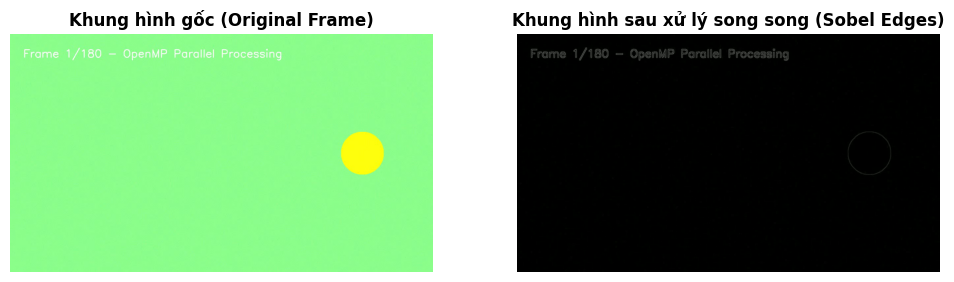

In [7]:
# Trích xuất 1 frame từ video gốc và video đã xử lý để xem trực tiếp trong notebook
cap_in = cv2.VideoCapture("sample_video.mp4")
cap_out = cv2.VideoCapture("test_result.mp4")

ret_in, frame_in = cap_in.read()
ret_out, frame_out = cap_out.read()

if ret_in and ret_out:
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(frame_in, cv2.COLOR_BGR2RGB))
    plt.title("Khung hình gốc (Original Frame)", fontweight='bold')
    plt.axis('off')
    
    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(frame_out, cv2.COLOR_BGR2RGB))
    plt.title("Khung hình sau xử lý song song (Sobel Edges)", fontweight='bold')
    plt.axis('off')
    plt.show()
else:
    print("Không thể đọc khung hình từ video.")
    
cap_in.release()
cap_out.release()